In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Student_Marks.csv to Student_Marks.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Student_Marks.csv")

print(df.head())
print(df.shape)
print(df.info())


   number_courses  time_study   Marks
0               3       4.508  19.202
1               4       0.096   7.734
2               4       3.133  13.811
3               6       7.909  53.018
4               8       7.811  55.299
(100, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   number_courses  100 non-null    int64  
 1   time_study      100 non-null    float64
 2   Marks           100 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 2.5 KB
None


In [ ]:
#HANDLING MISSING VALUES
print(df.isnull().sum())
#df["Marks"] = df["Marks"].fillna(df["Marks"].mean()) --> to fill missing values with mean
#df = df.dropna() --> remove rows containing missing values

number_courses    0
time_study        0
Marks             0
dtype: int64


In [ ]:
print("Duplicates:", df.duplicated().sum())
#df = df.drop_duplicates() --> to remove duplicates

Duplicates: 0


In [ ]:
print(df.dtypes)


number_courses      int64
time_study        float64
Marks             float64
dtype: object


In [ ]:
print(df.describe())

       number_courses  time_study       Marks
count      100.000000  100.000000  100.000000
mean         5.290000    4.077140   24.417690
std          1.799523    2.372914   14.326199
min          3.000000    0.096000    5.609000
25%          4.000000    2.058500   12.633000
50%          5.000000    4.022000   20.059500
75%          7.000000    6.179250   36.676250
max          8.000000    7.957000   55.299000


In [ ]:
#  from sklearn.preprocessing import StandardScaler

# scaler = StandardScaler()

# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

# --> standardization

-----> do it for SVM or nueral networks and sometimes logistic regression, use only after train-test split

# MIN_MAX SCALING :
# from sklearn.preprocessing import MinMaxScaler

# scaler = MinMaxScaler()

# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop("Marks", axis=1)
y = df["Marks"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# 1

# Load

# Read the CSV file


# 2

# Inspect

# head, shape, info, describe


# 3

# Clean

# Missing values, duplicates, incorrect types


# 4

# Identify X and y

# Choose input features and the target


# 5

# Split

# Create training and testing sets


# 6

# Preprocess

# Encode and scale as needed, fitting transformations on training data only


# 7

# Train

# Create the assigned model and call fit()


# 8

# Predict and evaluate

# Use predict(), suitable metrics and graphs

**LINEAR REGRESSSION**

   number_courses  time_study   Marks
0               3       4.508  19.202
1               4       0.096   7.734
2               4       3.133  13.811
3               6       7.909  53.018
4               8       7.811  55.299
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   number_courses  100 non-null    int64  
 1   time_study      100 non-null    float64
 2   Marks           100 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 2.5 KB
None
number_courses    0
time_study        0
Marks             0
dtype: int64
Actual values: [16.106 36.653 16.606  8.924  9.742 51.142 12.209 54.321 42.036 19.202
 50.986 24.172  7.014 39.965 24.394 55.299 36.746 38.278 24.318  8.1  ]
Predicted values: [19.27278272 37.76035676 20.18779372  9.65670863 10.97508223 44.81200554
 13.34810968 47.62447209 37.01567001 22.30738483 44.48113375 28.335

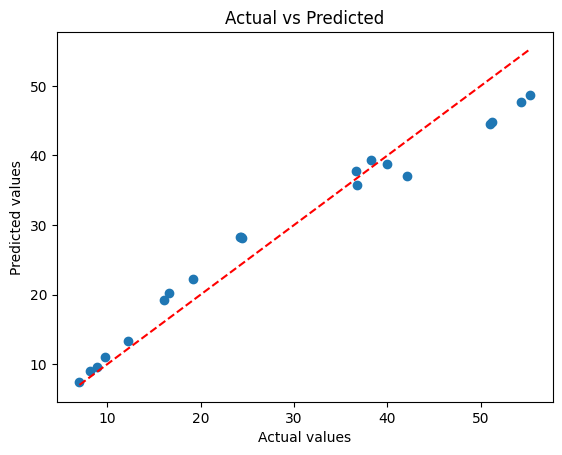

In [ ]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 2. Load dataset
df = pd.read_csv("Student_Marks.csv")

# 3. Inspect dataset
print(df.head())
print(df.info())
print(df.isnull().sum())

# 4. Basic cleaning
df = df.drop_duplicates()
df = df.dropna()

# 5. Separate features and target
target_col = "Marks"  # Change to your actual target column

X = df.drop(columns=[target_col])
y = df[target_col]

# Keep numerical input columns for this basic example
X = X.select_dtypes(include=np.number)

# 6. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 7. Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# 8. Predict
y_pred = model.predict(X_test)

print("Actual values:", y_test.to_numpy())
print("Predicted values:", y_pred)

# 9. Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

# 10. Visualize results
if X.shape[1] == 1:
    # One input feature: actual points and regression line
    feature = X.columns[0]
    X_plot = pd.DataFrame({
        feature: np.sort(X[feature].to_numpy())
    })

    plt.scatter(X[feature], y, label="Actual data")
    plt.plot(
        X_plot[feature],
        model.predict(X_plot),
        color="red",
        label="Regression line"
    )

    plt.xlabel(feature)
    plt.ylabel(target_col)
    plt.title("Linear Regression")
    plt.legend()
    plt.show()

else:
    # Multiple input features: actual vs predicted
    plt.scatter(y_test, y_pred)
    plt.xlabel("Actual values")
    plt.ylabel("Predicted values")
    plt.title("Actual vs Predicted")


    low = min(y_test.min(), y_pred.min())
    high = max(y_test.max(), y_pred.max())

    plt.plot([low, high], [low, high], "r--")
    plt.show()

**LINEAR REGRESSION WITH CORRELATION**


First five rows:
   number_courses  time_study   Marks
0               3       4.508  19.202
1               4       0.096   7.734
2               4       3.133  13.811
3               6       7.909  53.018
4               8       7.811  55.299

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   number_courses  100 non-null    int64  
 1   time_study      100 non-null    float64
 2   Marks           100 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 2.5 KB

Missing values:
number_courses    0
time_study        0
Marks             0
dtype: int64

Summary statistics:
       number_courses  time_study       Marks
count      100.000000  100.000000  100.000000
mean         5.290000    4.077140   24.417690
std          1.799523    2.372914   14.326199
min          3.000000    0.096000    5.609000
25%          

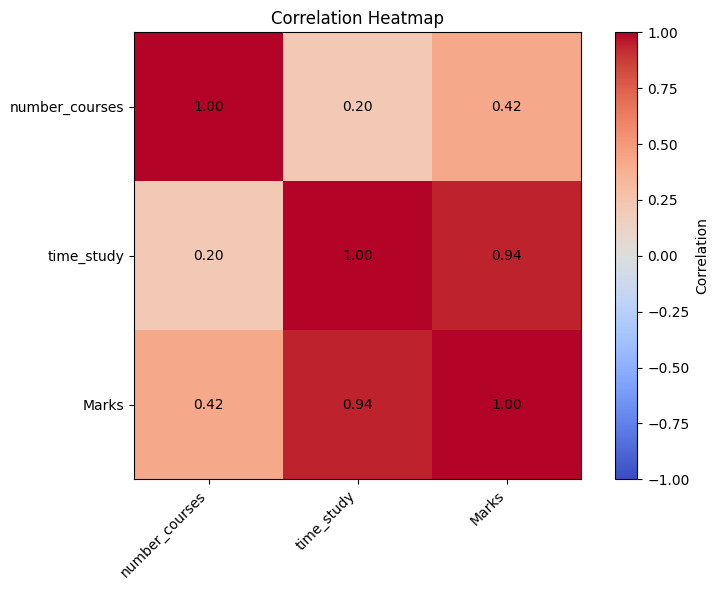


Features ranked by absolute training correlation:
time_study        0.934885
number_courses    0.365693
dtype: float64

Selected features: ['time_study', 'number_courses']

Intercept: -6.613046733912935
Coefficients: [5.16987176 1.87154988]

Actual values: [16.106 36.653 16.606  8.924  9.742 51.142 12.209 54.321 42.036 19.202
 50.986 24.172  7.014 39.965 24.394 55.299 36.746 38.278 24.318  8.1  ]
Predicted values: [19.27278272 37.76035676 20.18779372  9.65670863 10.97508223 44.81200554
 13.34810968 47.62447209 37.01567001 22.30738483 44.48113375 28.33573684
  7.42332402 38.70638699 28.10820618 48.74122069 35.72331468 39.30103485
 28.29432156  8.94326632]

MAE: 3.079345229666691
MSE: 14.200726136374612
RMSE: 3.7683850833446697
R2 Score: 0.9459936100591211


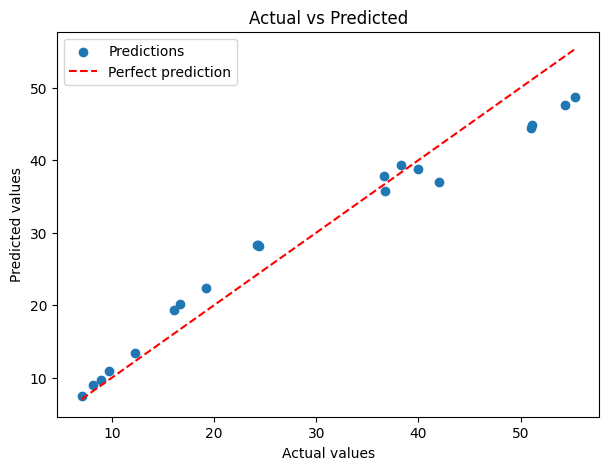

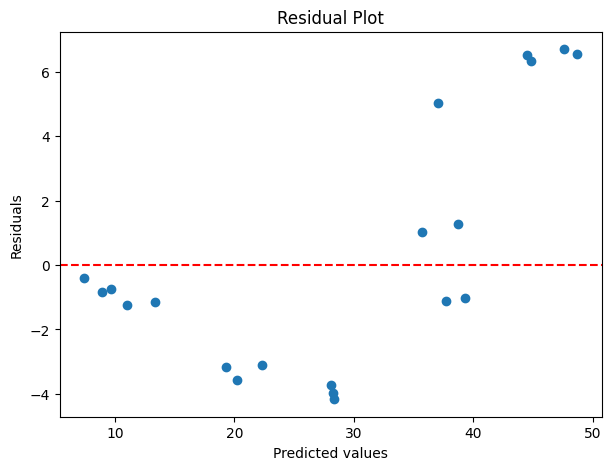

In [ ]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 2. Load dataset
df = pd.read_csv("Student_Marks.csv")

# 3. Inspect dataset
print("\nFirst five rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
print(df.describe())

# 4. Basic cleaning
df = df.drop_duplicates()

# Select the target column according to the question
target_col = "Marks"

# Remove rows with missing target values
df = df.dropna(subset=[target_col])

# Keep numerical input features for this basic program
X = df.drop(columns=[target_col])
X = X.select_dtypes(include=np.number)

y = pd.to_numeric(df[target_col], errors="coerce")

# Remove rows with invalid target values
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Fill missing numerical input values with column medians
X = X.fillna(X.median())

# Remove columns that contain no variation
X = X.loc[:, X.nunique() > 1]

if X.shape[1] == 0:
    raise ValueError("No usable numerical input features found.")

# 5. Correlation analysis
corr_data = pd.concat([X, y.rename(target_col)], axis=1)
corr_matrix = corr_data.corr(numeric_only=True)

print("\nCorrelation matrix:")
print(corr_matrix)

print("\nCorrelation with target:")
print(corr_matrix[target_col].drop(target_col).sort_values(
    key=abs, ascending=False
))

# Correlation heatmap
plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(corr_matrix.columns)),
           corr_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 6. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 7. Select features using training data correlations only
train_corr = X_train.corrwith(y_train).abs().dropna()
train_corr = train_corr.sort_values(ascending=False)

print("\nFeatures ranked by absolute training correlation:")
print(train_corr)

# Select the top 3 features, or fewer if unavailable
selected_features = train_corr.head(min(3, len(train_corr))).index.tolist()

print("\nSelected features:", selected_features)

X_train = X_train[selected_features]
X_test = X_test[selected_features]

# 8. Train the model
model = LinearRegression()
model.fit(X_train, y_train)

print("\nIntercept:", model.intercept_)
print("Coefficients:", model.coef_)

# 9. Predict
y_pred = model.predict(X_test)

print("\nActual values:", y_test.to_numpy())
print("Predicted values:", y_pred)

# 10. Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

# 11. Actual vs Predicted graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, label="Predictions")

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--",
         label="Perfect prediction")

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

# 12. Regression line if only one feature is selected
if len(selected_features) == 1:
    feature = selected_features[0]

    X_plot = pd.DataFrame({
        feature: np.linspace(X[feature].min(),
                             X[feature].max(), 100)
    })

    plt.figure(figsize=(7, 5))
    plt.scatter(X[feature], y, label="Actual data")
    plt.plot(X_plot[feature], model.predict(X_plot),
             color="red", label="Regression line")

    plt.xlabel(feature)
    plt.ylabel(target_col)
    plt.title("Linear Regression Line")
    plt.legend()
    plt.show()

# 13. Residual plot
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

LOGISTIC

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("your_file.csv")

# Basic cleaning
df = df.drop_duplicates()
df = df.dropna()

# Select features and target
X = df.drop(columns=["Result"])
y = df["Result"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

# Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create and train model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict classes
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'your_file.csv'

SVM CLASSIFICATION

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("your_file.csv")
df = df.drop_duplicates().dropna()

# Select features and target
X = df.drop(columns=["Result"])
y = df["Result"]  # e.g., 0 = Fail, 1 = Pass

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train SVM classifier
model = SVC(kernel="rbf")
model.fit(X_train, y_train)

# Predict classes
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Confusion matrix graph
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("SVM Classification - Confusion Matrix")
plt.show()

SVM REGRESSION

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

# Load dataset
df = pd.read_csv("your_file.csv")
df = df.drop_duplicates().dropna()

# Select features and target
X = df.drop(columns=["Marks"])
y = df["Marks"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train SVM regressor
model = SVR(kernel="rbf")
model.fit(X_train, y_train)

# Predict numerical values
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Actual vs predicted graph
plt.scatter(y_test, y_pred)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("SVM Regression - Actual vs Predicted")
plt.show()

DECISION TREE CLASSIFICATION

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Load dataset
df = pd.read_csv("your_file.csv")
df = df.drop_duplicates().dropna()

# Select features and target
X = df.drop(columns=["Result"])
y = df["Result"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

# Create model using Entropy
model = DecisionTreeClassifier(
    criterion="entropy", max_depth=4, random_state=42
)

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

# Decision tree visualization
plt.figure(figsize=(14, 8))
plot_tree(model, feature_names=X.columns,
          class_names=[str(c) for c in model.classes_],
          filled=True)
plt.show()

DECISION TREE REGRESSION

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("your_file.csv")
df = df.drop_duplicates().dropna()

# Select features and target
X = df.drop(columns=["Marks"])
y = df["Marks"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
model = DecisionTreeRegressor(
    criterion="squared_error", max_depth=4, random_state=42
)

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

# Actual vs predicted graph
plt.scatter(y_test, y_pred)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Decision Tree Regression")
plt.show()

# Visualize the tree
plt.figure(figsize=(14, 8))
plot_tree(model, feature_names=X.columns, filled=True)
plt.show()

RANDOM FOREST CLASSIFICATION

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("your_file.csv")
df = df.drop_duplicates().dropna()

# Features and target
X = df.drop(columns=["Result"])
y = df["Result"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

# Create model
model = RandomForestClassifier(
    n_estimators=100, random_state=42
)

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Random Forest Classification")
plt.show()

# Feature importance
importance = pd.Series(
    model.feature_importances_, index=X.columns
).sort_values()

importance.plot(kind="barh")
plt.title("Feature Importance")
plt.show()

RANDOM FOREST REGRESSION

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

# Load dataset
df = pd.read_csv("your_file.csv")
df = df.drop_duplicates().dropna()

# Features and target
X = df.drop(columns=["Marks"])
y = df["Marks"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
model = RandomForestRegressor(
    n_estimators=100, random_state=42
)

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)
print("R2 Score:", r2_score(y_test, y_pred))

# Actual vs predicted graph
plt.scatter(y_test, y_pred)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Random Forest Regression")
plt.show()

# Feature importance
pd.Series(
    model.feature_importances_, index=X.columns
).sort_values().plot(kind="barh")

plt.title("Feature Importance")
plt.show()

NUERAL NETWORK CLASSIFICATION

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("your_file.csv")
df = df.drop_duplicates().dropna()

# Features and target
X = df.drop(columns=["Result"])
y = df["Result"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create neural network
model = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    max_iter=1000,
    random_state=42
)

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Neural Network Classification")
plt.show()

# Training loss graph
plt.plot(model.loss_curve_)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Neural Network Training Loss")
plt.show()

NUERAL NETWORK REGRESION

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score
)

# Load dataset
df = pd.read_csv("your_file.csv")
df = df.drop_duplicates().dropna()

# Features and target
X = df.drop(columns=["Marks"])
y = df["Marks"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create neural network regressor
model = MLPRegressor(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    max_iter=1000,
    random_state=42
)

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluate
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Actual vs predicted graph
plt.scatter(y_test, y_pred)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Neural Network Regression")
plt.show()

# Training loss graph
plt.plot(model.loss_curve_)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Neural Network Training Loss")
plt.show()